============================================================
# EXCELR PROJECT
# Thinking Models vs Instruct Models
# DAY 21-23: GENERAL KNOWLEDGE Q&A
# 50 Questions × 4 Models = 200 Responses
 ============================================================

In [1]:
!pip install -q openai pandas

In [2]:
import pandas as pd
import time
from openai import OpenAI

In [ ]:
OPENROUTER_API_KEY = ""

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY
)

In [9]:
MODELS = {
    "DeepSeek-R1": "deepseek/deepseek-r1",

    "o3": "openai/o3",

    "GPT-4o-mini": "openai/gpt-4o-mini",

    "Llama-3.1-8B-Instruct":
        "meta-llama/llama-3.1-8b-instruct"
}

In [10]:
questions = [

    "What is the capital of Japan?",

    "Which planet is known as the Red Planet?",

    "Who wrote the novel Pride and Prejudice?",

    "What is the largest ocean on Earth?",

    "How many continents are there on Earth?",

    "What is the chemical symbol for gold?",

    "Who painted the Mona Lisa?",

    "What is the largest planet in our solar system?",

    "What is the boiling point of water at sea level in Celsius?",

    "Which country is famous for the Great Wall?",

    "What is the smallest prime number?",

    "Who was the first person to walk on the Moon?",

    "What is the currency of the United Kingdom?",

    "Which gas do humans need to breathe to survive?",

    "What is the capital of Australia?",

    "How many sides does a hexagon have?",

    "Who developed the theory of relativity?",

    "What is the largest mammal in the world?",

    "Which organ pumps blood throughout the human body?",

    "What is the hardest natural substance on Earth?",

    "Which country gifted the Statue of Liberty to the United States?",

    "What is the main language spoken in Brazil?",

    "How many bones are there in an adult human body?",

    "Which planet is closest to the Sun?",

    "Who wrote Romeo and Juliet?",

    "What is the largest desert in the world?",

    "What is H2O commonly known as?",

    "Which instrument is used to measure temperature?",

    "What is the capital of Canada?",

    "Which animal is commonly known as the King of the Jungle?",

    "What is the process by which plants convert sunlight into energy called?",

    "How many players are there on a standard football soccer team on the field?",

    "What is the currency of Japan?",

    "Which is the longest river in India?",

    "Who discovered penicillin?",

    "What is the nearest star to Earth?",

    "Which metal is liquid at room temperature?",

    "What is the capital of France?",

    "How many degrees are in a right angle?",

    "Which country is known as the Land of the Rising Sun?",

    "What is the largest internal organ in the human body?",

    "Which planet is famous for its prominent ring system?",

    "What is the study of earthquakes called?",

    "Who is credited with inventing the telephone?",

    "What is the freezing point of water in Celsius?",

    "Which is the largest country in the world by land area?",

    "What is the capital of Italy?",

    "Which vitamin is primarily produced by the skin when exposed to sunlight?",

    "What is the basic unit of life?",

    "Which blood cells are primarily responsible for fighting infections?"
]


print("Number of questions:", len(questions))

Number of questions: 50


In [11]:
def ask_model(model_id, question):

    prompt = f"""
Answer this general knowledge question clearly.

Question:
{question}
"""

    start = time.perf_counter()

    try:

        response = client.chat.completions.create(
            model=model_id,
            messages=[
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=0
        )

        end = time.perf_counter()

        return {
            "answer": response.choices[0].message.content,
            "response_time": round(end - start, 3),
            "error": ""
        }

    except Exception as e:

        end = time.perf_counter()

        return {
            "answer": "",
            "response_time": round(end - start, 3),
            "error": str(e)
        }

In [12]:
results = []

for question_number, question in enumerate(
    questions,
    start=1
):

    print(f"\nQuestion {question_number}/50")

    for model_name, model_id in MODELS.items():

        print(f"Testing {model_name}...")

        result = ask_model(
            model_id,
            question
        )

        results.append({
            "question_number": question_number,
            "question": question,
            "model": model_name,
            "answer": result["answer"],
            "response_time_seconds":
                result["response_time"],
            "error": result["error"],

            # Fill these after reviewing answers
            "accuracy": "",
            "clarity": "",
            "reasoning_observation": ""
        })

        time.sleep(1)


Question 1/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 2/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 3/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 4/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 5/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 6/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 7/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 8/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 9/50
Testing DeepSeek-R1...
Testing o3...
Testing GPT-4o-mini...
Testing Llama-3.1-8B-Instruct...

Question 10/50
Testing Deep

In [13]:
df = pd.DataFrame(results)

print("\nTotal responses:", len(df))

display(df.head())

df.to_csv(
    "qa_task_results.csv",
    index=False
)

print("\nSaved: qa_task_results.csv")


Total responses: 200


,question_number,question,model,answer,response_time_seconds,error,accuracy,clarity,reasoning_observation
0,1,What is the capital of Japan?,DeepSeek-R1,None,15.593,,,,
1,1,What is the capital of Japan?,o3,Tokyo,1.236,,,,
2,1,What is the capital of Japan?,GPT-4o-mini,The capital of Japan is Tokyo.,0.601,,,,
3,1,What is the capital of Japan?,Llama-3.1-8B-Instruct,The capital of Japan is Tokyo.,0.146,,,,
4,2,Which planet is known as the Red Planet?,DeepSeek-R1,\nThe planet known as the **Red Planet** is **...,13.927,,,,



Saved: qa_task_results.csv


In [20]:
comparison = df.groupby("model").agg(
    Accuracy=("accuracy", "mean"),
    Average_Response_Time=("response_time_seconds", "mean")
).reset_index()

comparison["Accuracy"] *= 100
comparison = comparison.round(2)

display(comparison)

,model,Accuracy,Average_Response_Time
0,DeepSeek-R1,50.0,16.01
1,GPT-4o-mini,90.0,0.94
2,Llama-3.1-8B-Instruct,98.0,0.92
3,o3,94.0,1.54


In [27]:
print("\nModels sorted by Accuracy (highest first):")
display(comparison.sort_values(by="Accuracy", ascending=False).reset_index(drop=True))


Models sorted by Accuracy (highest first):


,model,Accuracy,Average_Response_Time
0,Llama-3.1-8B-Instruct,98.0,0.92
1,o3,94.0,1.54
2,GPT-4o-mini,90.0,0.94
3,DeepSeek-R1,50.0,16.01


### Visualizing Model Performance

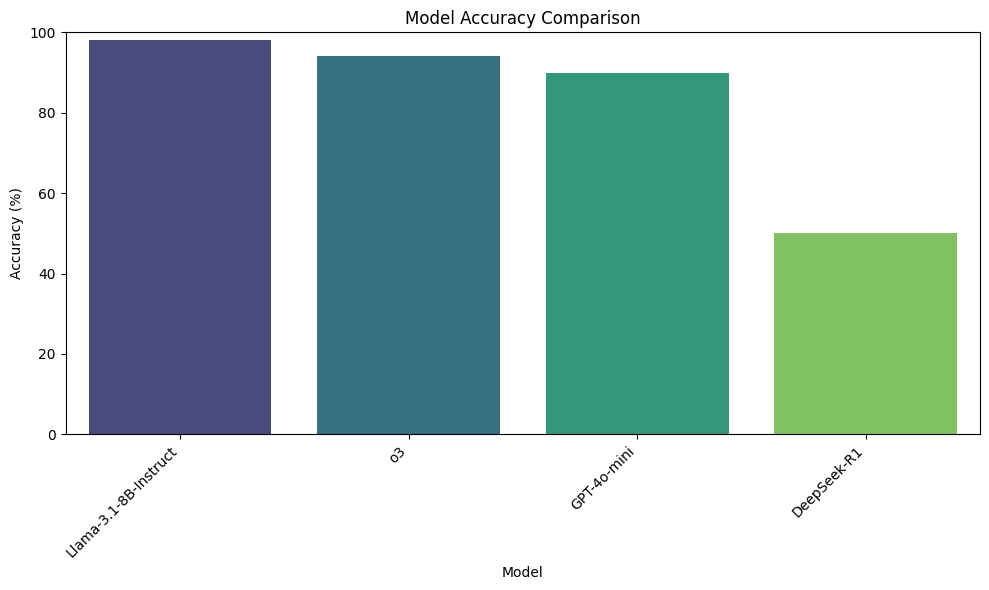

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart for Accuracy
fig1 = plt.figure(figsize=(10, 6))
sns.barplot(x='model', y='Accuracy', data=comparison.sort_values(by='Accuracy', ascending=False), palette='viridis', hue='model', legend=False)
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

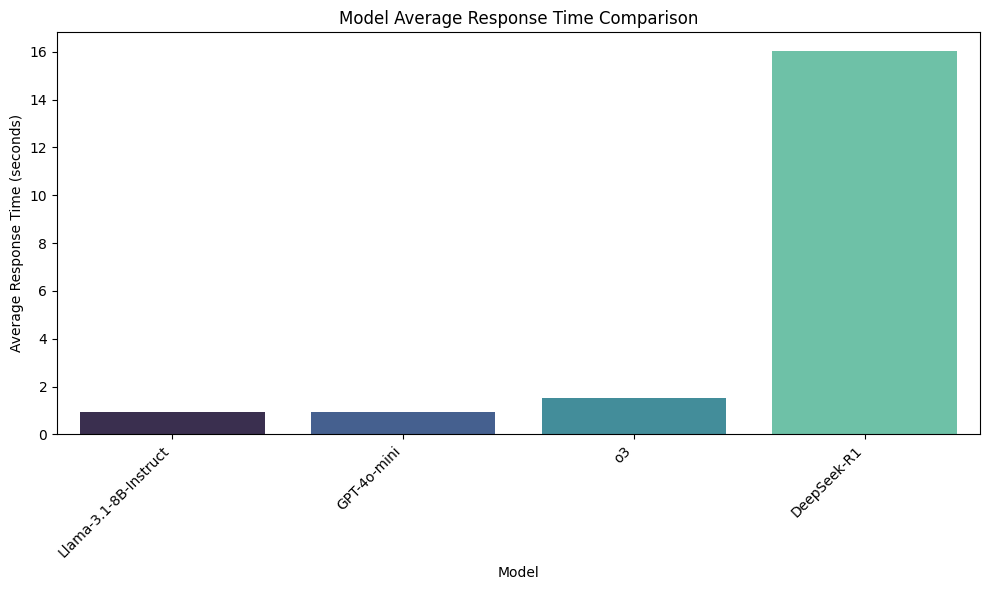

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart for Average Response Time
fig2 = plt.figure(figsize=(10, 6))
sns.barplot(x='model', y='Average_Response_Time', data=comparison.sort_values(by='Average_Response_Time'), palette='mako', hue='model', legend=False)
plt.title('Model Average Response Time Comparison')
plt.xlabel('Model')
plt.ylabel('Average Response Time (seconds)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Based on the comparison, here is a short summary of which model performed best on each task:

**Accuracy:** Llama-3.1-8B-Instruct achieved the highest accuracy at 98.0%.

**Average Response Time:** Llama-3.1-8B-Instruct also had the fastest average response time at 0.92 seconds, closely followed by GPT-4o-mini at 0.94 seconds.